# 02 · EDA inicial ORCA

Exploración descriptiva de los datos curados de SECOP II para identificar patrones, concentración, comportamiento temporal y señales relevantes para ORCA.

**Entrada:** `data/curated/`  
**Salida:** tablas, visualizaciones e insights para apoyar la priorización de riesgos.

## 1. Configuración

El notebook detecta automáticamente la raíz del proyecto para poder ejecutarse desde la carpeta del proyecto o desde `notebooks/`.

In [1]:
from pathlib import Path
import glob
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

ROOT = Path.cwd()
if not (ROOT / 'data').exists() and (ROOT.parent / 'data').exists():
    ROOT = ROOT.parent

CURATED = ROOT / 'data' / 'curated'
IMG = ROOT / 'dashboard' / 'eda'
IMG.mkdir(parents=True, exist_ok=True)

assert CURATED.exists(), f'No existe {CURATED}'

print('Raíz del proyecto:', ROOT)
print('Datos curados:', CURATED)

Raíz del proyecto: c:\Users\57317\Desktop\Data Office Strategy\Proyecto Final - Data Office Strategy\DataOfficeStrategy_Project_202620UPB
Datos curados: c:\Users\57317\Desktop\Data Office Strategy\Proyecto Final - Data Office Strategy\DataOfficeStrategy_Project_202620UPB\data\curated


## 2. Carga del dataset curado

In [2]:
archivos = sorted(CURATED.glob('*.parquet'))
if not archivos:
    raise FileNotFoundError('No se encontraron archivos Parquet en data/curated.')

print('Archivos encontrados:')
for archivo in archivos:
    print(f' - {archivo.name}')

# Preferir el dataset de contratos (DS-01).
candidatos = [a for a in archivos if 'DS-01' in a.name.lower() or 'contratos' in a.name.lower()]
archivo_eda = candidatos[0] if candidatos else archivos[0]

df = pd.read_parquet(archivo_eda)

print(f'\nDataset seleccionado: {archivo_eda.name}')
print(f'Filas: {len(df):,}')
print(f'Columnas: {df.shape[1]:,}')

Archivos encontrados:
 - DS-01_contratos_curated.parquet

Dataset seleccionado: DS-01_contratos_curated.parquet
Filas: 291,719
Columnas: 76


## 3. Perfil general

In [3]:
perfil = pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'no_nulos': df.notna().sum(),
    'nulos': df.isna().sum(),
    'porcentaje_nulos': (df.isna().mean() * 100).round(2),
    'unicos': df.nunique(dropna=True)
}).sort_values('porcentaje_nulos', ascending=False)

display(perfil.head(20))

,tipo,no_nulos,nulos,porcentaje_nulos,unicos
criterios_de_sostenibilidad_ambiental,string,4724,286995,98.38,2
fecha_de_notificaci_n_de_prorrogaci_n,datetime64[ns],17880,273839,93.87,1146
fecha_fin_liquidacion,datetime64[ns],45194,246525,84.51,2241
fecha_inicio_liquidacion,datetime64[ns],45188,246531,84.51,1591
proveedor_nit,string,54628,237091,81.27,10354
proveedor_nombre,string,54724,236995,81.24,10453
representante_legal_id,string,80117,211602,72.54,20465
ordenador_pago_id,string,158397,133322,45.70,2278
ultima_actualizacion,datetime64[ns],161487,130232,44.64,961
condiciones_de_entrega,string,194838,96881,33.21,20


## 4. Variables clave disponibles

Esta celda identifica nombres reales de columnas para evitar asumir que el dataset mantiene exactamente la nomenclatura de la fuente.

In [4]:
terminos = {
    'fecha': ['fecha_de_firma', 'fecha_firma'],
    'valor': ['valor_del_contrato', 'valor_contrato'],
    'modalidad': ['modalidad_de_contratacion'],
    'municipio': ['ciudad', 'municipio'],
    'entidad': ['nombre_entidad'],
    'proveedor': ['proveedor_id', 'proveedor_nombre'],
    'contrato': ['id_contrato']
}

def buscar_columna(opciones):
    for col in opciones:
        if col in df.columns:
            return col
    return None

COL = {k: buscar_columna(v) for k, v in terminos.items()}
pd.DataFrame({'variable': COL.keys(), 'columna_en_dataset': COL.values()})

,variable,columna_en_dataset
0,fecha,fecha_de_firma
1,valor,valor_del_contrato
2,modalidad,modalidad_de_contratacion
3,municipio,ciudad
4,entidad,nombre_entidad
5,proveedor,proveedor_id
6,contrato,id_contrato


## 5. Preparación de variables analíticas

In [5]:
fecha_col = COL['fecha']
valor_col = COL['valor']

if fecha_col:
    df['_fecha_eda'] = pd.to_datetime(df[fecha_col], errors='coerce')

if valor_col:
    df['_valor_eda'] = pd.to_numeric(df[valor_col], errors='coerce')

if fecha_col:
    print('Rango temporal:', df['_fecha_eda'].min(), '→', df['_fecha_eda'].max())
if valor_col:
    print('Valor total:', f"${df['_valor_eda'].sum():,.0f}")
    print('Valor mediano:', f"${df['_valor_eda'].median():,.0f}")

Rango temporal: 2024-01-01 00:00:00 → 2026-10-20 00:00:00
Valor total: $56,790,616,787,363
Valor mediano: $20,000,000


## 6. Evolución temporal de la contratación

Permite identificar cambios en el volumen y valor contratado a través del tiempo.

,periodo,contratos,valor_total
19,2025-08-01,7343,1659205490190.100098
20,2025-09-01,7912,1611718581932.119873
21,2025-10-01,7460,3058708896107.189941
22,2025-11-01,6232,3892392888726.52002
23,2025-12-01,3762,1667165158737.320068
24,2026-01-01,48964,4733402975451.660156
25,2026-02-01,1356,553954511035.619995
26,2026-03-01,1725,417366836532.280029
27,2026-04-01,1359,444074784666.349976
28,2026-05-01,1353,349061056569.190002


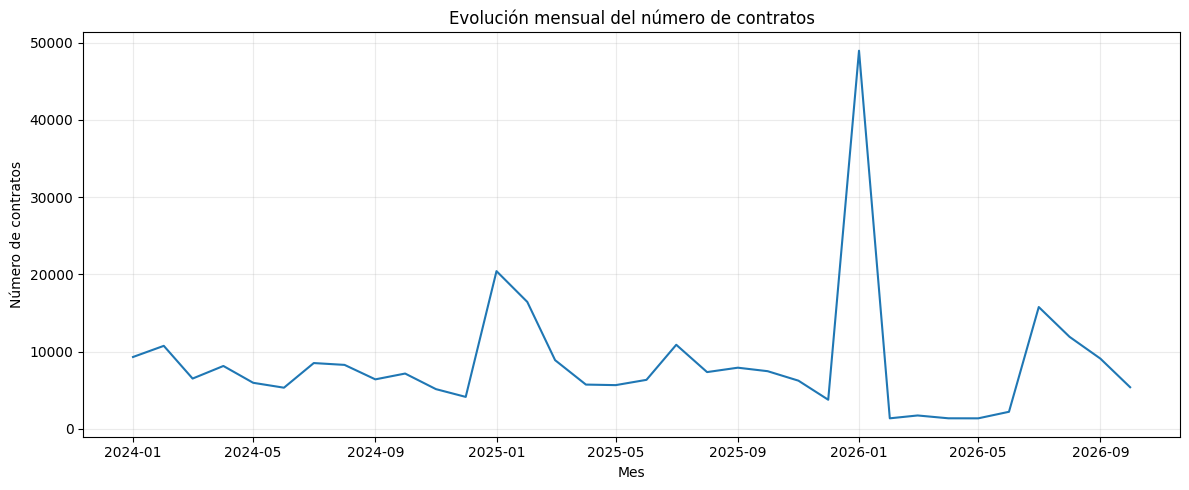

In [6]:
if fecha_col:
    temporal = (
        df.dropna(subset=['_fecha_eda'])
          .assign(periodo=lambda x: x['_fecha_eda'].dt.to_period('M').dt.to_timestamp())
          .groupby('periodo', as_index=False)
          .agg(contratos=('_fecha_eda', 'size'), valor_total=('_valor_eda', 'sum'))
    )

    display(temporal.tail(15))

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(temporal['periodo'], temporal['contratos'])
    ax.set_title('Evolución mensual del número de contratos')
    ax.set_xlabel('Mes')
    ax.set_ylabel('Número de contratos')
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(IMG / '01_evolucion_contratos.png', dpi=160, bbox_inches='tight')
    plt.show()

## 7. Modalidad de contratación

La modalidad es una variable prioritaria para ORCA porque permite observar la composición de la contratación y focalizar modalidades de interés, incluida la contratación directa.

,contratos,valor_total
modalidad_de_contratacion,,
Contratación directa,240507,23626043312374.539062
Contratación régimen especial,20987,6614391428511.009766
Mínima cuantía,15801,558329484121.619995
Contratación Directa (con ofertas),5982,14575057881911.359375
Contratación régimen especial (con ofertas),2853,3620288083716.290039
Selección abreviada subasta inversa,2650,1910596188867.280029
Selección Abreviada de Menor Cuantía,1815,744124928248.26001
Licitación pública,487,2636537406781.200195
Concurso de méritos abierto,336,282621760839.840027


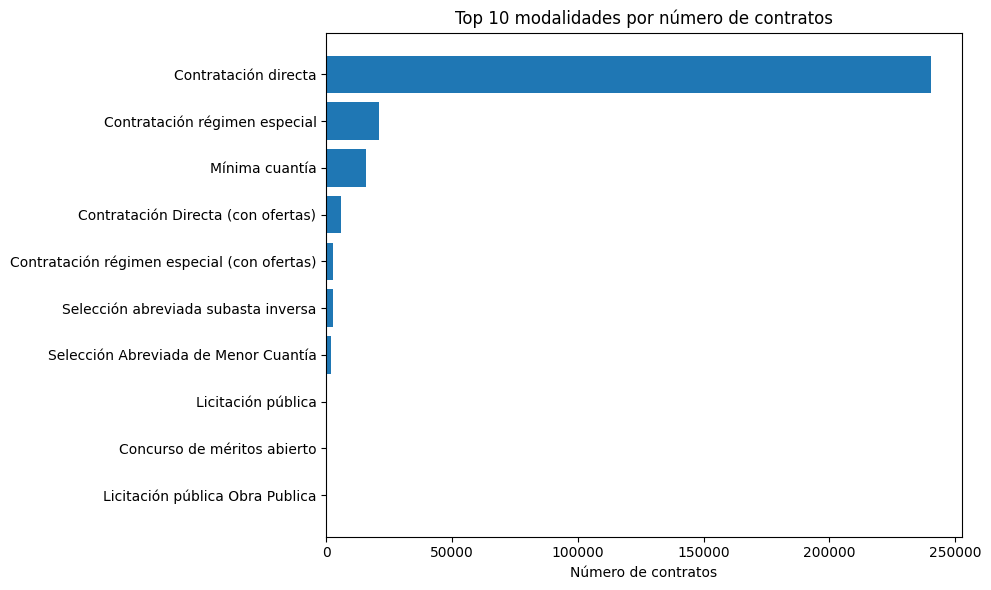

In [7]:
modalidad_col = COL['modalidad']

if modalidad_col:
    modalidad = (
        df.groupby(modalidad_col, dropna=False)
          .agg(contratos=(modalidad_col, 'size'), valor_total=('_valor_eda', 'sum'))
          .sort_values('contratos', ascending=False)
    )
    display(modalidad.head(15))

    top = modalidad.head(10).sort_values('contratos')
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(top.index.astype(str), top['contratos'])
    ax.set_title('Top 10 modalidades por número de contratos')
    ax.set_xlabel('Número de contratos')
    fig.tight_layout()
    fig.savefig(IMG / '02_modalidades.png', dpi=160, bbox_inches='tight')
    plt.show()

## 8. Distribución territorial

Se analiza la concentración de contratos por municipio para detectar territorios con mayor actividad y posibles focos de análisis.

,contratos,valor_total
ciudad,,
Medellín,133885,36056110824587.632812
<NA>,19695,3007201356819.080078
Envigado,11384,2180413897997.199951
Bello,10257,1124968375474.449951
Sabaneta,9056,667632690752.030029
Rionegro,6752,1667551934499.100098
La Estrella,5605,369448134526.98999
Apartadó,5205,490771788436.77002
Caldas,3520,170834988257.579987


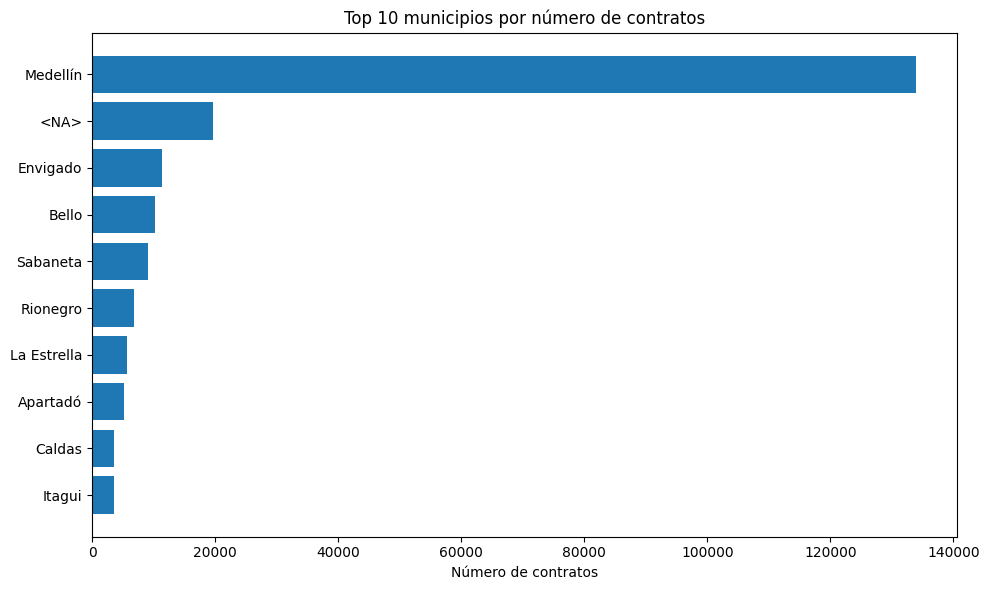

In [8]:
municipio_col = COL['municipio']

if municipio_col:
    municipio = (
        df.groupby(municipio_col, dropna=False)
          .agg(contratos=(municipio_col, 'size'), valor_total=('_valor_eda', 'sum'))
          .sort_values('contratos', ascending=False)
    )
    display(municipio.head(15))

    top = municipio.head(10).sort_values('contratos')
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(top.index.astype(str), top['contratos'])
    ax.set_title('Top 10 municipios por número de contratos')
    ax.set_xlabel('Número de contratos')
    fig.tight_layout()
    fig.savefig(IMG / '03_municipios.png', dpi=160, bbox_inches='tight')
    plt.show()

## 9. Entidades contratantes

Se identifica qué entidades concentran mayor número de contratos y valor contratado.

,contratos,valor_total
nombre_entidad,,
INSTITUCIÓN UNIVERSITARIA ITM,46400,1096222555162.060059
INSTITUTO DE DEPORTES Y RECREACION DE MEDELLIN,15968,2813680087098.02002
SENA REGIONAL ANTIOQUIA Grupo de Apoyo Administrativo Mixto,15737,947629749004.660034
Institución Universitaria Pascual Bravo COMPRADOR,13469,482204411311.48999
INSTITUCIÓN UNIVERSITARIA COLEGIO MAYOR DE ANTIOQUIA,8520,233239036864.390015
MUNICIPIO DE SABANETA,7650,633005441274.01001
DISTRITO ESPECIAL DE CIENCIA TECNOLOGIA E INNOVACION DE MEDELLIN,6283,15082286690823.369141
ALCALDÍA MUNICIPIO DE BELLO,6037,817385123668.609985
ICBF REGIONAL ANTIOQUIA,5531,2693865308561.919922


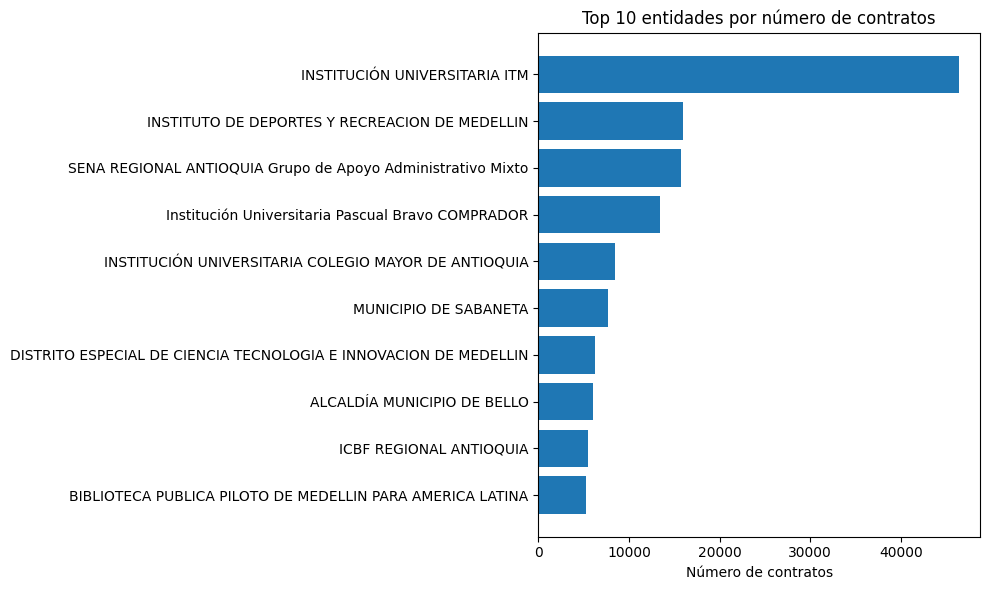

In [9]:
entidad_col = COL['entidad']

if entidad_col:
    entidades = (
        df.groupby(entidad_col, dropna=False)
          .agg(contratos=(entidad_col, 'size'), valor_total=('_valor_eda', 'sum'))
          .sort_values('contratos', ascending=False)
    )
    display(entidades.head(15))

    top = entidades.head(10).sort_values('contratos')
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(top.index.astype(str), top['contratos'])
    ax.set_title('Top 10 entidades por número de contratos')
    ax.set_xlabel('Número de contratos')
    fig.tight_layout()
    fig.savefig(IMG / '04_entidades.png', dpi=160, bbox_inches='tight')
    plt.show()

## 10. Concentración de proveedores

La concentración de contratos en pocos proveedores puede ser una señal útil para priorizar análisis, especialmente cuando se combina posteriormente con entidad, modalidad, valor y periodo.

,contratos,valor_total
proveedor_id,,
6c0ccfed9f9afaa2,369,71328130907.550003
b30bcc880fc4ed4d,304,33237567195.509998
92d38842ca953704,296,475148400288.0
29a41ca0259fb76f,246,143868317910.5
a84096e3b3140d00,234,7947080894.0
7e380e81f2d8948e,232,1213438945966.0
a0c1ddce79c1d776,221,99067992387.229996
093d6addfd463c91,216,51269356224.050003
78a2b3b261379a6e,210,30678466908.720001


Participación de los 10 proveedores con más contratos (excluyendo registros sin proveedor): 0.86%


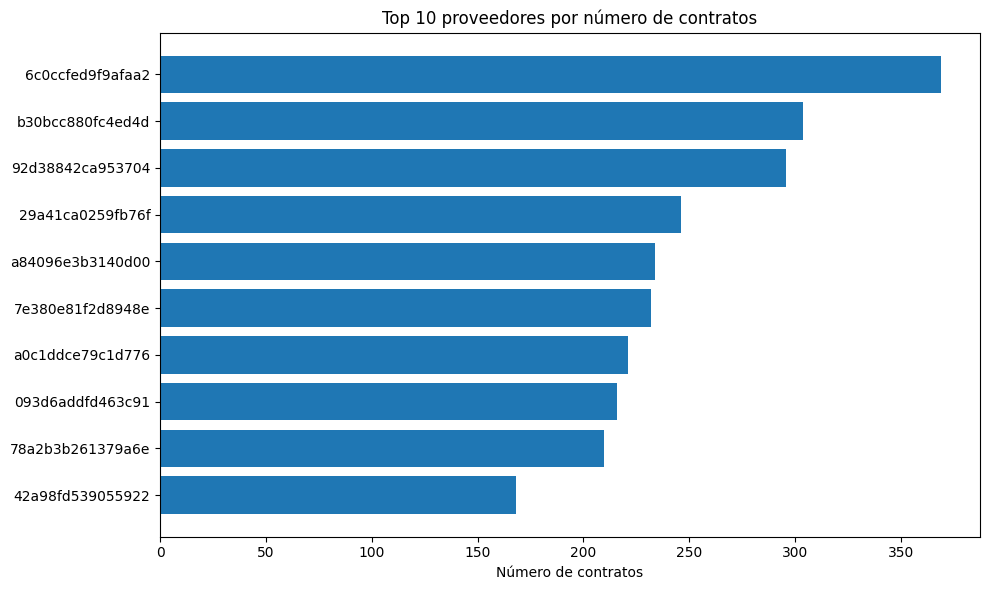

In [11]:
proveedor_col = COL['proveedor']

if proveedor_col:
    df_prov = df[df[proveedor_col].notna()].copy()

    proveedores = (
        df_prov.groupby(proveedor_col)
          .agg(
              contratos=(proveedor_col, 'size'),
              valor_total=('_valor_eda', 'sum')
          )
          .sort_values('contratos', ascending=False)
    )

    display(proveedores.head(20))

    top_n = min(10, len(proveedores))
    share = proveedores.head(top_n)['contratos'].sum() / len(df_prov) * 100

    print(
        f'Participación de los {top_n} proveedores con más contratos '
        f'(excluyendo registros sin proveedor): {share:.2f}%'
    )

    top = proveedores.head(10).sort_values('contratos')

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(top.index.astype(str), top['contratos'])
    ax.set_title('Top 10 proveedores por número de contratos')
    ax.set_xlabel('Número de contratos')
    fig.tight_layout()

    fig.savefig(
        IMG / '05_proveedores.png',
        dpi=160,
        bbox_inches='tight'
    )

    plt.show()

## 11. Valores atípicos

Se utiliza el rango intercuartílico (IQR) como señal exploratoria. Esto **no implica por sí mismo irregularidad**: los valores deben interpretarse junto con modalidad, entidad, proveedor y contexto.

In [12]:
if valor_col:
    valores = df['_valor_eda'].dropna()
    valores = valores[valores >= 0]
    q1 = valores.quantile(0.25)
    q3 = valores.quantile(0.75)
    iqr = q3 - q1
    limite = q3 + 1.5 * iqr
    atipicos = df[df['_valor_eda'] > limite].copy()

    print(f'Q1: ${q1:,.0f}')
    print(f'Q3: ${q3:,.0f}')
    print(f'Límite superior IQR: ${limite:,.0f}')
    print(f'Registros sobre el límite: {len(atipicos):,} ({len(atipicos)/len(df)*100:.2f}%)')

    columnas_mostrar = [c for c in [COL['contrato'], entidad_col, proveedor_col, modalidad_col, municipio_col, valor_col] if c]
    display(atipicos[columnas_mostrar].sort_values(valor_col, ascending=False).head(20))

Q1: $10,432,177
Q3: $38,901,752
Límite superior IQR: $81,606,116
Registros sobre el límite: 29,379 (10.07%)


,id_contrato,nombre_entidad,proveedor_id,modalidad_de_contratacion,ciudad,valor_del_contrato
21672,CO1.PCCNTR.9953923,INSTITUTO DE DEPORTES Y RECREACION DE MEDELLIN,cca2806d82e30597,Contratación directa,Medellín,1159397606948.0
277640,CO1.PCCNTR.7171517,DEPARTAMENTO DE ANTIOQUIA,92782a59d814748b,Contratación Directa (con ofertas),Medellín,712569236855.0
39350,CO1.PCCNTR.7969114,DEPARTAMENTO DE ANTIOQUIA,451fe42141f29328,Contratación Directa (con ofertas),Medellín,552273854028.0
7890,CO1.PCCNTR.8618650,DISTRITO ESPECIAL DE CIENCIA TECNOLOGIA E INNO...,2e9cd66678e692ff,Contratación directa,Medellín,503210859577.0
187236,CO1.PCCNTR.7047524,DISTRITO ESPECIAL DE CIENCIA TECNOLOGIA E INNO...,2e9cd66678e692ff,Contratación directa,Medellín,491372098658.0
117408,CO1.PCCNTR.8258264,DISTRITO ESPECIAL DE CIENCIA TECNOLOGIA E INNO...,cca2806d82e30597,Contratación Directa (con ofertas),Medellín,407534750024.0
214679,CO1.PCCNTR.7862082,DEPARTAMENTO DE ANTIOQUIA,2b55eed7c0f362dc,Contratación directa,Medellín,358016126603.0
23016,CO1.PCCNTR.7250064,DISTRITO ESPECIAL DE CIENCIA TECNOLOGIA E INNO...,4046f9171ac30485,Contratación Directa (con ofertas),Medellín,337477752507.0
83832,CO1.PCCNTR.6451319,SUBCUENTA DEL SISTEMA DE PARQUES NACIONALES NA...,e0160b7c32c008e7,Contratación Directa (con ofertas),<NA>,330000000000.0
125677,CO1.PCCNTR.8424777,DISTRITO ESPECIAL DE CIENCIA TECNOLOGIA E INNO...,4bc350f40843d10f,Contratación directa,Medellín,296539017355.0


## 12. Señales temporales de consistencia

Se cuantifican las banderas generadas durante la limpieza para conocer su presencia en el dataset curado.

In [19]:
flags = [
    'flag_valor_cero',
    'flag_valor_atipico',
    'flag_fechas_inconsistentes',
    'flag_sin_fecha_firma'
]

resumen_flags = []

for flag in flags:
    if flag in df.columns:
        n = int(df[flag].fillna(False).astype(bool).sum())
        resumen_flags.append({
            'regla': flag,
            'casos': n,
            'porcentaje': round(n / len(df) * 100, 4)
        })

resumen_flags = pd.DataFrame(resumen_flags)

display(resumen_flags)

,regla,casos,porcentaje
0,flag_valor_cero,2809,0.9629
1,flag_valor_atipico,47,0.0161
2,flag_fechas_inconsistentes,85,0.0291
3,flag_sin_fecha_firma,0,0.0000


## 13. Concentración: entidad × proveedor

Se buscan relaciones con alta cantidad de contratos entre una entidad y un proveedor. Esta señal es exploratoria y debe combinarse con valor, modalidad y periodo antes de considerarse prioritaria.

In [20]:
if entidad_col and proveedor_col:
    concentracion = (
        df.groupby([entidad_col, proveedor_col], dropna=False)
          .agg(contratos=(COL['contrato'] if COL['contrato'] else entidad_col, 'size'),
               valor_total=('_valor_eda', 'sum'))
          .sort_values('contratos', ascending=False)
          .reset_index()
    )
    display(concentracion.head(20))

,nombre_entidad,proveedor_id,contratos,valor_total
0,EMPRESA DE DESARROLLO URBANO DE MEDELLIN,<NA>,223,699235626627.0
1,DISTRITO ESPECIAL DE CIENCIA TECNOLOGIA E INNO...,7e380e81f2d8948e,182,988566772578.0
2,ASOCIACIÓN DE MUNICIPIOS DEL NORTE ANTIOQUEÑO-...,42a98fd539055922,160,40977369005.599998
3,MUNICIPIO DE SEGOVIA,be6c0d30dd2c5a36,112,12988395549.0
4,MUNICIPIO DE GUATAPE,a0c1ddce79c1d776,107,35379747381.57
5,ALCALDIA DE EL PEÑOL,b0550a2bbe64c837,99,24854630420.709999
6,ALCALDIA ALEJANDRIA,659aec7f3cb56fad,91,5643262455.3
7,MUNICIPIO DE PUERTO TRIUNFO,a5d3b3c49cd3ae7f,89,3445158727.0
8,DISTRITO ESPECIAL DE CIENCIA TECNOLOGIA E INNO...,92d38842ca953704,88,229355950528.0
9,ALCALDÍA MUNICIPIO DE BELLO,4f1cf27409a2036a,87,244532965322.0


## 14. Resumen ejecutivo de señales

### Resumen ejecutivo de señales

1. **¿Dónde se concentra la contratación?**  
La contratación presenta una alta concentración territorial y económica en Medellín. El municipio concentra aproximadamente el **45,9 % de los contratos y el 63,5 % del valor total contratado**. Además, el Distrito Especial de Ciencia, Tecnología e Innovación de Medellín representa cerca del **26,6 % del valor total**, aunque concentra solamente alrededor del 2,2 % de los contratos. Esto evidencia que el volumen de contratos y la exposición económica no necesariamente se comportan de la misma manera.

2. **¿Qué modalidades predominan y cuál merece priorización?**  
Predomina ampliamente la **contratación directa**. Al agrupar contratación directa y contratación directa con ofertas, estas modalidades representan aproximadamente el **84,5 % de los contratos y el 67,3 % del valor total**. Por su alta participación, la modalidad de contratación directa constituye una variable relevante para la priorización de análisis en ORCA, aunque por sí sola no representa evidencia de irregularidad.

3. **¿Qué entidades/proveedores concentran actividad?**  
Las entidades con mayor volumen de contratos incluyen instituciones como el **ITM, el Instituto de Deportes y Recreación de Medellín y el SENA Regional Antioquia**. Sin embargo, el análisis entidad–proveedor muestra que la frecuencia no siempre coincide con la exposición económica: existen relaciones con un número moderado de contratos pero valores acumulados elevados. Por ello, ORCA debería considerar simultáneamente el **número de contratos y el valor acumulado por entidad y proveedor**.

4. **¿Qué señales atípicas o temporales aparecen?**  
Se identificaron **29.379 contratos (10,07 %) por encima del límite superior del IQR**, lo que representa valores estadísticamente altos, pero no necesariamente irregulares. En contraste, la regla estricta de calidad marcó **47 contratos como valores atípicos**, además de **2.809 contratos con valor cero** y **85 registros con inconsistencias de fechas**. También se observa una fuerte variabilidad temporal: enero de 2026 concentra 48.964 contratos, por lo que este comportamiento debe considerarse como una señal exploratoria que requiere contextualización antes de interpretarse como anomalía.

5. **¿Qué variables deberían alimentar el modelo/ranking de riesgo de ORCA?**  
Los resultados sugieren utilizar un enfoque multidimensional que combine **modalidad de contratación, valor del contrato, concentración territorial, entidad contratante, proveedor, frecuencia de contratación, valor acumulado por relación entidad–proveedor y comportamiento temporal**. También pueden incorporarse las **inconsistencias de fechas, valores cero y señales de valores atípicos** como variables complementarias para priorizar casos de revisión. Estas variables deben utilizarse para generar señales y priorizar análisis, no como evidencia automática de irregularidad.